Датасет

https://www.kaggle.com/datasets/shreyapmaher/fruits-dataset-images

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

In [ ]:
from sklearn.model_selection import train_test_split
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root_directory = Path("images/")
images = []
labels = []
dataset_structure = {}

def scan_directory():
    if not root_directory.exists():
        raise FileNotFoundError(f"Директория {root_directory} не найдена")
    
    for category_path in root_directory.iterdir():
        if category_path.is_dir():                
            for file_path in category_path.iterdir():
                if file_path.suffix.lower() in {'.jpg', '.jpeg'}:
                    img = cv2.imread(str(file_path))
                    if img is not None:
                        images.append(img)
                        labels.append(category_path.name)
                        
                        flipped = cv2.flip(img, 1)
                        images.append(flipped)
                        labels.append(category_path.name)
    return images
    
    
scan_directory()

labels_idx = {'apple': 0, 'banana': 1, 'cherry': 2, 'chickoo': 3, 'grapes': 4, 'kiwi': 5, 'orange': 6, 'strawberry': 7}
    
X_train, X_temp, y_train, y_temp = train_test_split(
    images, labels,
    test_size=0.3,
    random_state=42,
    stratify=labels
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

y_train = np.array([labels_idx[label] for label in y_train])
y_valid = np.array([labels_idx[label] for label in y_valid])


IMG_SIZE = (28, 28)

X_train = [cv2.resize(img, IMG_SIZE) for img in X_train]
X_valid = [cv2.resize(img, IMG_SIZE) for img in X_valid]

X_train = np.array(X_train)
X_valid = np.array(X_valid)

In [10]:
import keras

n_classes = 8

X_train = X_train.reshape(-1, 28, 28, 3).astype("float32") / 255
X_valid = X_valid.reshape(-1, 28, 28, 3).astype("float32") / 255

y_train = keras.utils.to_categorical(y_train, n_classes)
y_valid = keras.utils.to_categorical(y_valid, n_classes)

display(X_train[0])
display(y_train[0])

array([[[1.        , 1.        , 1.        ],
        [1.        , 1.        , 1.        ],
        [1.        , 1.        , 1.        ],
        ...,
        [1.        , 1.        , 1.        ],
        [1.        , 1.        , 1.        ],
        [1.        , 1.        , 1.        ]],

       [[0.99607843, 0.99607843, 0.99607843],
        [0.99607843, 0.99607843, 0.99607843],
        [0.99607843, 0.99607843, 0.99607843],
        ...,
        [1.        , 1.        , 1.        ],
        [1.        , 1.        , 1.        ],
        [0.99607843, 0.99607843, 0.99607843]],

       [[1.        , 1.        , 1.        ],
        [1.        , 1.        , 1.        ],
        [1.        , 1.        , 1.        ],
        ...,
        [1.        , 1.        , 1.        ],
        [1.        , 1.        , 1.        ],
        [1.        , 1.        , 1.        ]],

       ...,

       [[1.        , 1.        , 1.        ],
        [0.99607843, 0.99607843, 0.99607843],
        [0.99607843, 0

array([0., 0., 0., 0., 0., 1., 0., 0.])

In [ ]:
from keras.layers import Conv2D, Dense, Dropout, Flatten, InputLayer, MaxPooling2D
from keras.models import Sequential
from keras import layers


data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

lenet_model = Sequential()

lenet_model.add(InputLayer(shape=(28, 28, 3)))

lenet_model.add(data_augmentation)

lenet_model.add(Conv2D(32, kernel_size=(3, 3), activation="relu"))

lenet_model.add(Conv2D(64, kernel_size=(3, 3), activation="relu"))
lenet_model.add(MaxPooling2D(pool_size=(2, 2)))
lenet_model.add(Dropout(0.25))

lenet_model.add(Flatten())
lenet_model.add(Dense(128, activation="relu"))
lenet_model.add(Dropout(0.5))

lenet_model.add(Dense(n_classes, activation="softmax"))

lenet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 28, 28, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,200,200 (4.58 MB)

 Trainable params: 1,200,200 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
lenet_model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

history = lenet_model.fit(
    X_train,
    y_train,
    batch_size=128,
    epochs=10,
    validation_data=(X_valid, y_valid),
)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.1224 - loss: 2.1307 - val_accuracy: 0.2088 - val_loss: 2.0183
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.2447 - loss: 1.9876 - val_accuracy: 0.3407 - val_loss: 1.8758
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.3247 - loss: 1.8591 - val_accuracy: 0.2967 - val_loss: 1.7309
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.4047 - loss: 1.6922 - val_accuracy: 0.4176 - val_loss: 1.5627
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.4847 - loss: 1.5080 - val_accuracy: 0.3846 - val_loss: 1.5045
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.4729 - loss: 1.4793 - val_accuracy: 0.5165 - val_loss: 1.3244
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.4706 - loss: 1.3903 - val_accuracy: 0.4835 - val_loss: 1.2756
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.5271 - loss: 1.3007 - val_accuracy: 0.5824 - val_loss: 1.2031

In [19]:
lenet_model.evaluate(X_valid, y_valid)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6264 - loss: 1.1022


[1.102236270904541, 0.6263736486434937]

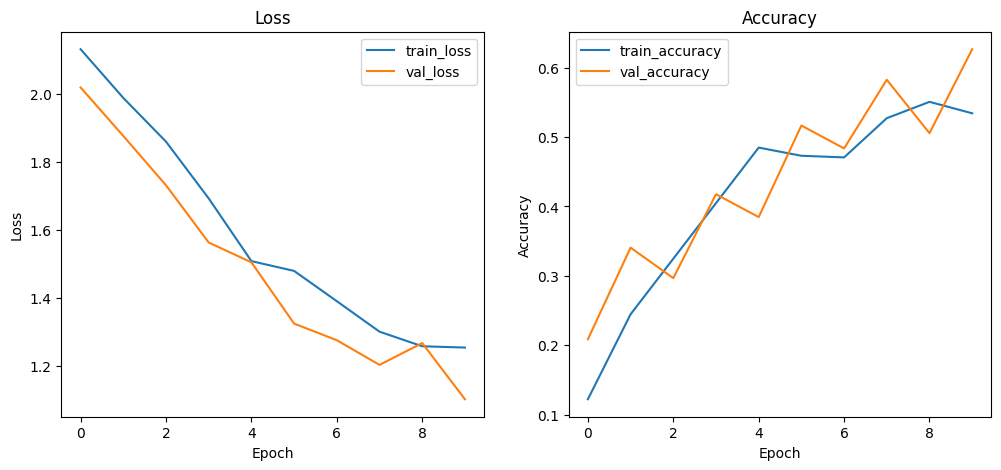

In [20]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train_accuracy")
plt.plot(history.history["val_accuracy"], label="val_accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()


Перенос обучения с VGG19

In [34]:
import keras

random_seed = 42
keras.utils.set_random_seed(random_seed)

batch_size = 64
target_size = (224, 224)

train = keras.utils.image_dataset_from_directory(
    directory="./images",
    validation_split=0.2,
    subset="training",
    seed=random_seed,
    image_size=target_size,
    batch_size=batch_size,
    color_mode="rgb",
    label_mode="categorical",
    shuffle=True,
)

valid = keras.utils.image_dataset_from_directory(
    directory="./images",
    validation_split=0.2,
    subset="validation",
    seed=random_seed,
    image_size=target_size,
    batch_size=batch_size,
    color_mode="rgb",
    label_mode="categorical",
    shuffle=True,
)

data_augmentation_tl = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

class_names = train.class_names 
print(f"Имена классов: {class_names}")

Found 320 files belonging to 8 classes.
Using 256 files for training.
Found 320 files belonging to 8 classes.
Using 64 files for validation.
Имена классов: ['apple', 'banana', 'cherry', 'chickoo', 'grapes', 'kiwi', 'orange', 'strawberry']


In [24]:
from keras.applications.vgg19 import VGG19

vgg19 = VGG19(include_top=False, weights="imagenet", input_shape=(224, 224, 3), pooling=None)

vgg19.trainable = False

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 15s 0us/step


In [ ]:
from keras.layers import Dense, Dropout, Flatten
from keras.models import Sequential

tl_model = Sequential()

tl_model = Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation_tl,
    layers.Rescaling(1./255),
    vgg19,
    Flatten(name="flattened"),
    Dropout(0.5, name="dropout"),
    Dense(8, activation="softmax", name="predictions")
])


In [36]:
tl_model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

tl_model.fit(x=train, validation_data=valid, epochs=3)
tl_model.save("models/tl_model.keras")

Epoch 1/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 125s 34s/step - accuracy: 0.1836 - loss: 3.1740 - val_accuracy: 0.4531 - val_loss: 1.5596
Epoch 2/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 118s 37s/step - accuracy: 0.4453 - loss: 1.7660 - val_accuracy: 0.5469 - val_loss: 1.2600
Epoch 3/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 46s 9s/step - accuracy: 0.5742 - loss: 1.1871 - val_accuracy: 0.6250 - val_loss: 1.0082


In [37]:
tl_model.evaluate(valid)

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step - accuracy: 0.6250 - loss: 1.0082


[1.008228063583374, 0.625]

In [39]:
from skimage.feature import hog
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.svm import SVC

from sklearn.model_selection import train_test_split
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root_directory = Path("images/")
images = []
labels = []
dataset_structure = {}

def scan_directory():
    if not root_directory.exists():
        raise FileNotFoundError(f"Директория {root_directory} не найдена")
    
    for category_path in root_directory.iterdir():
        if category_path.is_dir():                
            for file_path in category_path.iterdir():
                if file_path.suffix.lower() in {'.jpg', '.jpeg'}:
                    img = cv2.imread(str(file_path))
                    if img is not None:
                        images.append(img)
                        labels.append(category_path.name)
                        
                        flipped = cv2.flip(img, 1)
                        images.append(flipped)
                        labels.append(category_path.name)
    return images
    
    
scan_directory()

labels_idx = {'apple': 0, 'banana': 1, 'cherry': 2, 'chickoo': 3, 'grapes': 4, 'kiwi': 5, 'orange': 6, 'strawberry': 7}

images_resize = []
for img in images:
    resized = cv2.resize(img, (128, 128))
    images_resize.append(resized)
    
    
X_train, X_temp, y_train, y_temp = train_test_split(
    images_resize, labels,
    test_size=0.3,     
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

def apply_threshold(img):
    resized = cv2.resize(img, (128, 128))
    grey = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    gaussian_new = cv2.GaussianBlur(grey, (0, 0), sigmaX=2)
    mean_val = gaussian_new.mean()
    _, labeled_mask = cv2.threshold(gaussian_new, mean_val, 255, cv2.THRESH_BINARY)
    
    return labeled_mask

def threshold_features(img):
    mask = apply_threshold(img)
    return mask.flatten()

def extract_hog_features(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    features = hog(gray,
                   pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2),
                   orientations=9,
                   block_norm='L2-Hys')
    return features

X_train_hog = np.array([extract_hog_features(img) for img in X_train])
X_val_hog   = np.array([extract_hog_features(img) for img in X_val])
    

svm_hog = SVC(kernel='rbf', C=10, gamma='scale')
svm_hog.fit(X_train_hog, y_train)

y_pred_hog = svm_hog.predict(X_val_hog)
acc_hog = accuracy_score(y_val, y_pred_hog)
    
print("Accuracy (HOG + SVM):", acc_hog)



Accuracy (HOG + SVM): 0.5164835164835165


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6264 - loss: 1.1022
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.6250 - loss: 1.0082


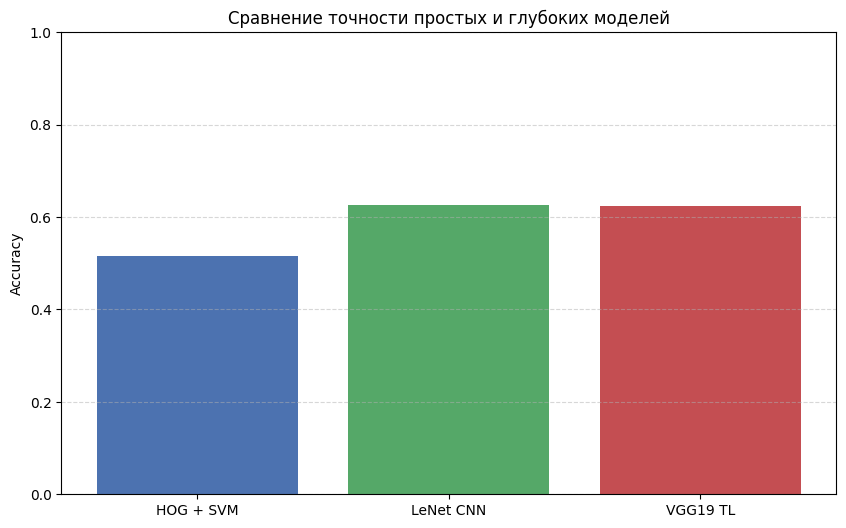

In [41]:
import matplotlib.pyplot as plt

loss_lenet, acc_lenet = lenet_model.evaluate(X_valid, y_valid)
loss_vgg, acc_vgg = tl_model.evaluate(valid)


import matplotlib.pyplot as plt

methods = [
    "HOG + SVM",
    "LeNet CNN",
    "VGG19 TL"
]

accuracies = [
    acc_hog,
    acc_lenet,
    acc_vgg
]

plt.figure(figsize=(10, 6))
plt.bar(methods, accuracies, color=["#4C72B0", "#55A868", "#C44E52"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Сравнение точности простых и глубоких моделей")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

